In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled")


PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [2]:

BASE = "/kaggle/input/datasets/kanzallahhoussam/qvhighlight/QVHighlight"

print("Dataset exists:", os.path.exists(BASE))

print("\nDataset folders:")
if os.path.exists(BASE):
    for folder in os.listdir(BASE):
        path = os.path.join(BASE, folder)
        print(folder, "->", os.listdir(path)[:10] if os.path.isdir(path) else "File")
else:
    print("Dataset path not found. Check the Kaggle input path.")


Dataset exists: True

Dataset folders:
annotations -> ['LICENSE', 'README.md', 'highlight_test_release.jsonl', 'highlight_train_release.jsonl', 'highlight_val_release.jsonl', 'subs_train.jsonl']
features -> ['clip_features', 'clip_sub_features', 'clip_text_features', 'pann_features', 'slowfast_features']


In [3]:

ANNOTATION_DIR = os.path.join(BASE, "annotations")

VIDEO_DIR = os.path.join(BASE, "features", "clip_features")

TEXT_DIR = os.path.join(BASE, "features", "clip_text_features")

SLOWFAST_DIR = os.path.join(BASE, "features", "slowfast_features")

print("Annotation directory:", os.path.exists(ANNOTATION_DIR))
print("CLIP video features:", os.path.exists(VIDEO_DIR))
print("CLIP text features:", os.path.exists(TEXT_DIR))
print("SlowFast features:", os.path.exists(SLOWFAST_DIR))

print("\nNumber of files:")

print("Annotations:", len(os.listdir(ANNOTATION_DIR)))
print("CLIP video:", len(os.listdir(VIDEO_DIR)))
print("CLIP text:", len(os.listdir(TEXT_DIR)))
print("SlowFast:", len(os.listdir(SLOWFAST_DIR)))


Annotation directory: True
CLIP video features: True
CLIP text features: True
SlowFast features: True

Number of files:
Annotations: 6
CLIP video: 12562
CLIP text: 10311
SlowFast: 12562


In [4]:

def load_jsonl(file_path):
    records = []

    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))

    return records


train_path = os.path.join(
    ANNOTATION_DIR, "highlight_train_release.jsonl"
)

val_path = os.path.join(
    ANNOTATION_DIR, "highlight_val_release.jsonl"
)

test_path = os.path.join(
    ANNOTATION_DIR, "highlight_test_release.jsonl"
)

train_records = load_jsonl(train_path)
val_records = load_jsonl(val_path)
test_records = load_jsonl(test_path)

print("Training samples:", len(train_records))
print("Validation samples:", len(val_records))
print("Testing samples:", len(test_records))

print("\nKeys in annotation:")
print(train_records[0].keys())

print("\nFirst training sample:")
print(train_records[0])


Training samples: 7218
Validation samples: 1550
Testing samples: 1542

Keys in annotation:
dict_keys(['qid', 'query', 'duration', 'vid', 'relevant_clip_ids', 'saliency_scores', 'relevant_windows'])

First training sample:
{'qid': 9769, 'query': 'some military patriots takes us through their safety procedures and measures.', 'duration': 150, 'vid': 'j7rJstUseKg_360.0_510.0', 'relevant_clip_ids': [36, 37, 38, 39, 40, 42, 43, 44, 45, 46, 48, 49, 50, 51, 52, 54, 55, 56, 57, 58, 60, 61, 62, 63, 64, 68, 69, 70, 72], 'saliency_scores': [[4, 3, 2], [4, 1, 3], [4, 3, 4], [4, 1, 2], [4, 2, 2], [4, 2, 2], [4, 2, 2], [4, 2, 2], [4, 1, 2], [4, 1, 3], [4, 3, 4], [4, 3, 3], [4, 3, 3], [4, 3, 4], [4, 3, 2], [4, 1, 2], [4, 3, 2], [4, 1, 2], [4, 1, 2], [4, 1, 2], [4, 1, 2], [3, 3, 3], [4, 3, 4], [4, 1, 3], [4, 1, 2], [4, 1, 2], [4, 1, 2], [4, 1, 2], [4, 1, 2]], 'relevant_windows': [[72, 82], [84, 94], [96, 106], [108, 118], [120, 130], [136, 142], [144, 146]]}


In [6]:

# Select the first training sample
sample = train_records[0]

video_id = sample["vid"]
query_id = sample["qid"]

video_file = os.path.join(VIDEO_DIR, video_id + ".npz")
text_file = os.path.join(TEXT_DIR, f"qid{query_id}.npz")

print("Video ID:", video_id)
print("Query ID:", query_id)

# Load video features
video_data = np.load(video_file)

print("\nVideo feature keys:", video_data.files)

for key in video_data.files:
    print(key, "shape:", video_data[key].shape)

# Load query features
text_data = np.load(text_file)

print("\nText feature keys:", text_data.files)

for key in text_data.files:
    print(key, "shape:", text_data[key].shape)


Video ID: j7rJstUseKg_360.0_510.0
Query ID: 9769

Video feature keys: ['features']
features shape: (75, 512)

Text feature keys: ['last_hidden_state', 'pooler_output']
last_hidden_state shape: (14, 512)
pooler_output shape: (512,)


In [10]:

class QVHighlightsDataset(Dataset):

    def __init__(self, records):
        self.records = records
        self.valid_records = []

        for record in self.records:

            video_path = os.path.join(
                VIDEO_DIR, record["vid"] + ".npz"
            )

            text_path = os.path.join(
                TEXT_DIR, f"qid{record['qid']}.npz"
            )

            if os.path.exists(video_path) and os.path.exists(text_path):
                self.valid_records.append(record)

        print("Valid samples:", len(self.valid_records))
        print("Skipped samples:", len(self.records) - len(self.valid_records))

    def __len__(self):
        return len(self.valid_records)

    def __getitem__(self, index):

        record = self.valid_records[index]

        video_path = os.path.join(
            VIDEO_DIR, record["vid"] + ".npz"
        )

        text_path = os.path.join(
            TEXT_DIR, f"qid{record['qid']}.npz"
        )

        video_data = np.load(video_path)
        text_data = np.load(text_path)

        video_features = video_data["features"].astype(np.float32)
        query_features = text_data["pooler_output"].astype(np.float32)

        # Repeat query feature for every video clip
        query_repeated = np.repeat(
            query_features[np.newaxis, :],
            len(video_features),
            axis=0
        )

        # Combine video and query features
        combined_features = np.concatenate(
            [video_features, query_repeated],
            axis=1
        )

        num_clips = len(video_features)

        # Initialize ground-truth saliency scores
        targets = np.zeros(num_clips, dtype=np.float32)
        annotation_mask = np.zeros(num_clips, dtype=np.float32)

        for clip_id, scores in zip(
            record["relevant_clip_ids"],
            record["saliency_scores"]
        ):

            if 0 <= clip_id < num_clips:

                targets[clip_id] = np.mean(scores) / 4.0
                annotation_mask[clip_id] = 1.0

        return (
            torch.tensor(combined_features),
            torch.tensor(targets),
            torch.tensor(annotation_mask)
        )


In [11]:

train_dataset = QVHighlightsDataset(train_records)
val_dataset = QVHighlightsDataset(val_records)
test_dataset = QVHighlightsDataset(test_records)

print("\nDataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

# Inspect one sample
features, targets, mask = train_dataset[0]

print("\nSample information:")
print("Features:", features.shape)
print("Targets:", targets.shape)
print("Mask:", mask.shape)
print("Annotated clips:", int(mask.sum().item()))


Valid samples: 7218
Skipped samples: 0
Valid samples: 1550
Skipped samples: 0
Valid samples: 1542
Skipped samples: 0

Dataset sizes:
Train: 7218
Validation: 1550
Test: 1542

Sample information:
Features: torch.Size([75, 1024])
Targets: torch.Size([75])
Mask: torch.Size([75])
Annotated clips: 29


In [12]:

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

BATCH_SIZE = 32

def collate_fn(batch):

    features, targets, masks = zip(*batch)

    lengths = torch.tensor(
        [len(x) for x in features],
        dtype=torch.long
    )

    features = pad_sequence(
        features,
        batch_first=True,
        padding_value=0.0
    )

    targets = pad_sequence(
        targets,
        batch_first=True,
        padding_value=0.0
    )

    masks = pad_sequence(
        masks,
        batch_first=True,
        padding_value=0.0
    )

    return features, targets, masks, lengths


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

# Inspect one batch
x, y, mask, lengths = next(iter(train_loader))

print("\nBatch verification:")
print("Features:", x.shape)
print("Targets:", y.shape)
print("Masks:", mask.shape)
print("Lengths:", lengths.shape)
print("Device:", DEVICE)


Training batches: 226
Validation batches: 49
Testing batches: 49

Batch verification:
Features: torch.Size([32, 75, 1024])
Targets: torch.Size([32, 75])
Masks: torch.Size([32, 75])
Lengths: torch.Size([32])
Device: cuda


In [13]:

class QueryBiLSTM(nn.Module):

    def __init__(
        self,
        input_dim=1024,
        hidden_dim=256,
        num_layers=2,
        dropout=0.3
    ):
        super(QueryBiLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(hidden_dim * 2, 1)

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        output, _ = self.lstm(x)

        output = self.dropout(output)

        output = self.fc(output)

        output = self.sigmoid(output)

        return output.squeeze(-1)


model = QueryBiLSTM().to(DEVICE)

print(model)

print("\nTrainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

print("\nModel device:",
      next(model.parameters()).device)


QueryBiLSTM(
  (lstm): LSTM(1024, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

Trainable parameters: 4203009

Model device: cuda:0


In [14]:

with torch.no_grad():

    sample_input = x.to(DEVICE)

    predictions = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", predictions.shape)

print("Minimum score:", predictions.min().item())
print("Maximum score:", predictions.max().item())

assert predictions.shape == y.shape
assert predictions.min() >= 0
assert predictions.max() <= 1

print("\nBiLSTM model verified successfully!")


Input shape: torch.Size([32, 75, 1024])
Output shape: torch.Size([32, 75])
Minimum score: 0.4621632695198059
Maximum score: 0.5500243306159973

BiLSTM model verified successfully!


In [15]:

EPOCHS = 20
LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001
GRAD_CLIP = 1.0

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Masked Mean Squared Error
def compute_loss(predictions, targets, mask):

    squared_error = (predictions - targets) ** 2

    loss = (squared_error * mask).sum()

    loss = loss / mask.sum().clamp(min=1.0)

    return loss


print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Optimizer:", optimizer.__class__.__name__)
print("Loss function: Masked MSE")


Epochs: 20
Learning rate: 0.0001
Weight decay: 0.0001
Optimizer: AdamW
Loss function: Masked MSE


In [16]:

model.eval()

with torch.no_grad():

    sample_x, sample_y, sample_mask, sample_lengths = next(iter(train_loader))

    sample_x = sample_x.to(DEVICE)
    sample_y = sample_y.to(DEVICE)
    sample_mask = sample_mask.to(DEVICE)

    sample_predictions = model(sample_x)

    sample_loss = compute_loss(
        sample_predictions,
        sample_y,
        sample_mask
    )

print("Initial sample loss:", sample_loss.item())

assert torch.isfinite(sample_loss)

print("Loss function verified successfully!")


Initial sample loss: 0.08818326145410538
Loss function verified successfully!


In [17]:

from tqdm.auto import tqdm
import copy

best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "precision": [],
    "recall": [],
    "f1": [],
    "mae": []
}

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_sum = 0.0
    train_clip_count = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for x, y, mask, lengths in progress:
        x = x.to(DEVICE)
        y = y.to(DEVICE)
        mask = mask.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(x)
        loss = compute_loss(predictions, y, mask)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        valid_count = mask.sum().item()
        train_loss_sum += loss.item() * valid_count
        train_clip_count += valid_count

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_sum / max(train_clip_count, 1)

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_clip_count = 0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for x, y, mask, lengths in val_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)
            mask = mask.to(DEVICE)

            predictions = model(x)
            loss = compute_loss(predictions, y, mask)

            valid_count = mask.sum().item()
            val_loss_sum += loss.item() * valid_count
            val_clip_count += valid_count

            valid = mask > 0
            all_predictions.extend(predictions[valid].cpu().numpy())
            all_targets.extend(y[valid].cpu().numpy())

    val_loss = val_loss_sum / max(val_clip_count, 1)

    all_predictions = np.array(all_predictions)
    all_targets = np.array(all_targets)

    # Custom binary metrics using threshold 0.5
    pred_labels = (all_predictions >= 0.5).astype(int)
    true_labels = (all_targets >= 0.5).astype(int)

    accuracy = accuracy_score(true_labels, pred_labels)
    precision = precision_score(true_labels, pred_labels, zero_division=0)
    recall = recall_score(true_labels, pred_labels, zero_division=0)
    f1 = f1_score(true_labels, pred_labels, zero_division=0)
    mae = mean_absolute_error(all_targets, all_predictions)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["accuracy"].append(accuracy)
    history["precision"].append(precision)
    history["recall"].append(recall)
    history["f1"].append(f1)
    history["mae"].append(mae)

    # Save the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "/kaggle/working/qvhighlight_bilstm_best.pth")

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f} | "
        f"MAE: {mae:.4f}"
    )

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)
print("Best model saved successfully.")


Epoch 1/20:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 01/20 | Train Loss: 0.0322 | Val Loss: 0.0303 | Accuracy: 0.9100 | Precision: 0.9101 | Recall: 0.9998 | F1: 0.9528 | MAE: 0.1390


Epoch 2/20:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 02/20 | Train Loss: 0.0276 | Val Loss: 0.0297 | Accuracy: 0.9098 | Precision: 0.9101 | Recall: 0.9996 | F1: 0.9527 | MAE: 0.1345


Epoch 3/20:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 03/20 | Train Loss: 0.0260 | Val Loss: 0.0299 | Accuracy: 0.9081 | Precision: 0.9110 | Recall: 0.9963 | F1: 0.9517 | MAE: 0.1359


... (30 outputs left out)

Epoch 19/20:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 19/20 | Train Loss: 0.0101 | Val Loss: 0.0345 | Accuracy: 0.8979 | Precision: 0.9168 | Recall: 0.9764 | F1: 0.9456 | MAE: 0.1443


Epoch 20/20:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.0097 | Val Loss: 0.0343 | Accuracy: 0.8974 | Precision: 0.9171 | Recall: 0.9754 | F1: 0.9453 | MAE: 0.1442

Training completed!
Best validation loss: 0.029698534181010296
Best model saved successfully.


In [19]:

print("Total test records:", len(test_dataset))

labelled_records = [
    record for record in test_dataset.valid_records
    if "relevant_clip_ids" in record and "saliency_scores" in record
]

unlabelled_records = [
    record for record in test_dataset.valid_records
    if "relevant_clip_ids" not in record or "saliency_scores" not in record
]

print("Records with ground-truth labels:", len(labelled_records))
print("Records without ground-truth labels:", len(unlabelled_records))

if unlabelled_records:
    print("\nExample unlabelled record:")
    print(unlabelled_records[0].keys())


Total test records: 1542
Records with ground-truth labels: 0
Records without ground-truth labels: 1542

Example unlabelled record:
dict_keys(['qid', 'query', 'duration', 'vid'])


In [20]:

model.load_state_dict(
    torch.load(
        "/kaggle/working/qvhighlight_bilstm_best.pth",
        map_location=DEVICE
    )
)
model.eval()

val_predictions = []
val_targets = []

with torch.no_grad():
    for x, y, mask, lengths in val_loader:
        x = x.to(DEVICE)
        predictions = model(x).cpu().numpy()

        for i in range(len(y)):
            valid = mask[i].numpy() > 0
            val_predictions.extend(predictions[i][valid])
            val_targets.extend(y[i].numpy()[valid])

val_predictions = np.array(val_predictions)
val_targets = np.array(val_targets)

val_pred_labels = (val_predictions >= 0.5).astype(int)
val_true_labels = (val_targets >= 0.5).astype(int)

print("BEST CHECKPOINT - VALIDATION RESULTS")
print("-" * 40)
print("Accuracy:", round(accuracy_score(val_true_labels, val_pred_labels), 4))
print("Precision:", round(precision_score(val_true_labels, val_pred_labels, zero_division=0), 4))
print("Recall:", round(recall_score(val_true_labels, val_pred_labels, zero_division=0), 4))
print("F1 Score:", round(f1_score(val_true_labels, val_pred_labels, zero_division=0), 4))
print("MAE:", round(mean_absolute_error(val_targets, val_predictions), 4))


BEST CHECKPOINT - VALIDATION RESULTS
----------------------------------------
Accuracy: 0.9098
Precision: 0.9101
Recall: 0.9996
F1 Score: 0.9527
MAE: 0.1345


In [21]:

import math

test_highlights = []

model.eval()

with torch.no_grad():
    for record in tqdm(test_dataset.valid_records, desc="Generating highlights"):

        video_path = os.path.join(VIDEO_DIR, record["vid"] + ".npz")
        text_path = os.path.join(TEXT_DIR, f"qid{record['qid']}.npz")

        video_data = np.load(video_path)
        text_data = np.load(text_path)

        video_features = video_data["features"].astype(np.float32)
        query_features = text_data["pooler_output"].astype(np.float32)

        query_repeated = np.repeat(
            query_features[np.newaxis, :],
            len(video_features),
            axis=0
        )

        combined = np.concatenate(
            [video_features, query_repeated],
            axis=1
        )

        x = torch.tensor(combined).unsqueeze(0).to(DEVICE)
        scores = model(x).squeeze(0).cpu().numpy()

        total_clips = len(scores)
        selected_count = max(1, math.ceil(total_clips * 0.15))

        selected_indices = np.argsort(scores)[-selected_count:]
        selected_indices = sorted(selected_indices.tolist())

        test_highlights.append({
            "qid": record["qid"],
            "vid": record["vid"],
            "query": record["query"],
            "highlight_clip_indices": selected_indices,
            "saliency_scores": scores.tolist(),
            "compression_ratio": selected_count / total_clips
        })

print("Videos processed:", len(test_highlights))
print("Average compression ratio:",
      round(np.mean([x["compression_ratio"] for x in test_highlights]), 4))

print("\nExample prediction:")
print(test_highlights[0])


Generating highlights:   0%|          | 0/1542 [00:00<?, ?it/s]

Videos processed: 1542
Average compression ratio: 0.1599

Example prediction:
{'qid': 3158, 'vid': '_6hnl_BrFvs_360.0_510.0', 'query': 'A video covering hill and water from a boat', 'highlight_clip_indices': [46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57], 'saliency_scores': [0.6296042799949646, 0.65296870470047, 0.6604319214820862, 0.6622684001922607, 0.6686636805534363, 0.6527498960494995, 0.6508564949035645, 0.6482123732566833, 0.6514461040496826, 0.6578441858291626, 0.6754915714263916, 0.6813064813613892, 0.6939149498939514, 0.6956055164337158, 0.6974278688430786, 0.69130939245224, 0.6865472793579102, 0.6789296269416809, 0.6775817275047302, 0.6755595803260803, 0.6699261665344238, 0.6645076870918274, 0.6692971587181091, 0.671422004699707, 0.6695599555969238, 0.669285237789154, 0.6722914576530457, 0.6786466836929321, 0.6874735951423645, 0.6904429793357849, 0.6852638721466064, 0.6826426386833191, 0.6808358430862427, 0.675530731678009, 0.6857901215553284, 0.6877368688583374, 0.7207376

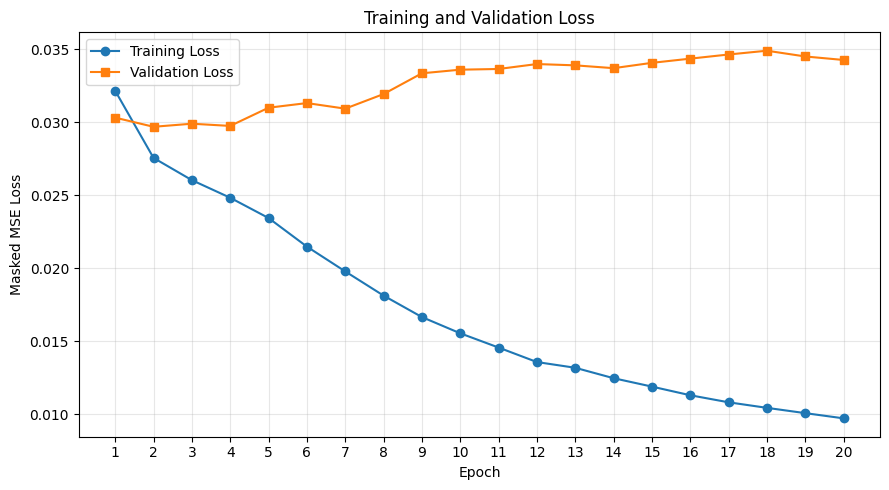

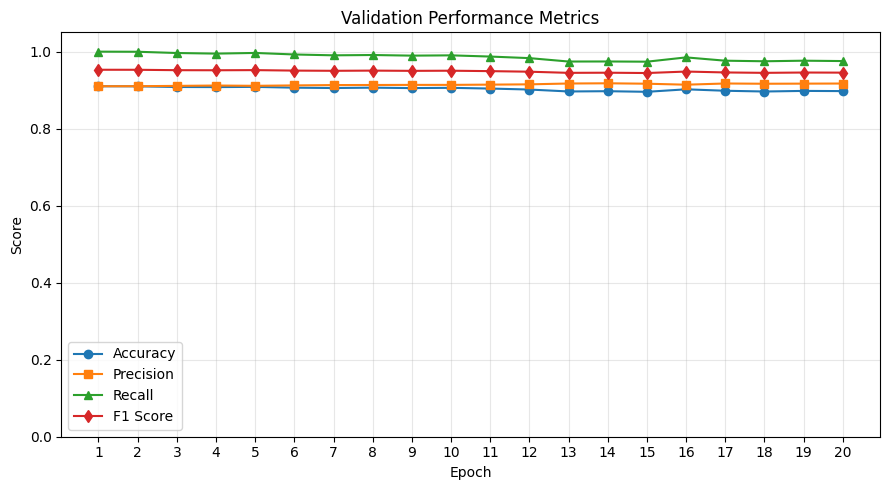

Both graphs saved successfully!


In [22]:

epochs = range(1, EPOCHS + 1)

# Graph 1: Training and Validation Loss
plt.figure(figsize=(9, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="s", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE Loss")
plt.title("Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/loss_graph.png", dpi=300)
plt.show()

# Graph 2: Evaluation Metrics
plt.figure(figsize=(9, 5))
plt.plot(epochs, history["accuracy"], marker="o", label="Accuracy")
plt.plot(epochs, history["precision"], marker="s", label="Precision")
plt.plot(epochs, history["recall"], marker="^", label="Recall")
plt.plot(epochs, history["f1"], marker="d", label="F1 Score")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance Metrics")
plt.xticks(list(epochs))
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/metrics_graph.png", dpi=300)
plt.show()

print("Both graphs saved successfully!")


In [23]:

import pandas as pd
import json
import os
import zipfile

OUTPUT_DIR = "/kaggle/working/qvhighlight_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Save training history
history_df = pd.DataFrame(history)
history_df.insert(0, "epoch", range(1, EPOCHS + 1))
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

# 2. Save test predictions
with open(os.path.join(OUTPUT_DIR, "test_highlights.json"), "w") as f:
    json.dump(test_highlights, f, indent=2)

# 3. Save a compact CSV of selected highlights
prediction_df = pd.DataFrame([
    {
        "qid": item["qid"],
        "vid": item["vid"],
        "query": item["query"],
        "highlight_clip_indices": ",".join(
            map(str, item["highlight_clip_indices"])
        ),
        "compression_ratio": item["compression_ratio"]
    }
    for item in test_highlights
])

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_highlights.csv"),
    index=False
)

# 4. Copy best model and graphs
import shutil

for filename in [
    "qvhighlight_bilstm_best.pth",
    "loss_graph.png",
    "metrics_graph.png"
]:
    source = os.path.join("/kaggle/working", filename)
    if os.path.exists(source):
        shutil.copy2(source, OUTPUT_DIR)

# 5. Create one ZIP file
zip_path = "/kaggle/working/QVHighlights_BiLSTM_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in os.listdir(OUTPUT_DIR):
        filepath = os.path.join(OUTPUT_DIR, filename)
        zipf.write(filepath, arcname=filename)

print("All results saved successfully!")
print("\nFiles included:")
for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

print("\nZIP file:", zip_path)
print("Total test predictions:", len(test_highlights))


All results saved successfully!

Files included:
- qvhighlight_bilstm_best.pth
- loss_graph.png
- test_highlights.csv
- metrics_graph.png
- training_history.csv
- test_highlights.json

ZIP file: /kaggle/working/QVHighlights_BiLSTM_Results.zip
Total test predictions: 1542


QVHIGHLIGHTS BiLSTM - LIVE DEMONSTRATION
Video ID: NUsG9BgSes0_210.0_360.0
Query: A girl and her mother cooked while talking with each other on facetime.
Video duration: 150 seconds
Total clips: 75
Selected highlight clips: [24, 31, 32, 33, 34, 35, 36, 37, 38, 39, 68, 69]
Number of selected clips: 12
Selection ratio: 0.16

SELECTED HIGHLIGHTS
Clip 24: Predicted saliency = 0.7510
Clip 31: Predicted saliency = 0.7599
Clip 32: Predicted saliency = 0.7567
Clip 33: Predicted saliency = 0.7576
Clip 34: Predicted saliency = 0.7572
Clip 35: Predicted saliency = 0.7615
Clip 36: Predicted saliency = 0.7622
Clip 37: Predicted saliency = 0.7663
Clip 38: Predicted saliency = 0.7612
Clip 39: Predicted saliency = 0.7545
Clip 68: Predicted saliency = 0.7512
Clip 69: Predicted saliency = 0.7515


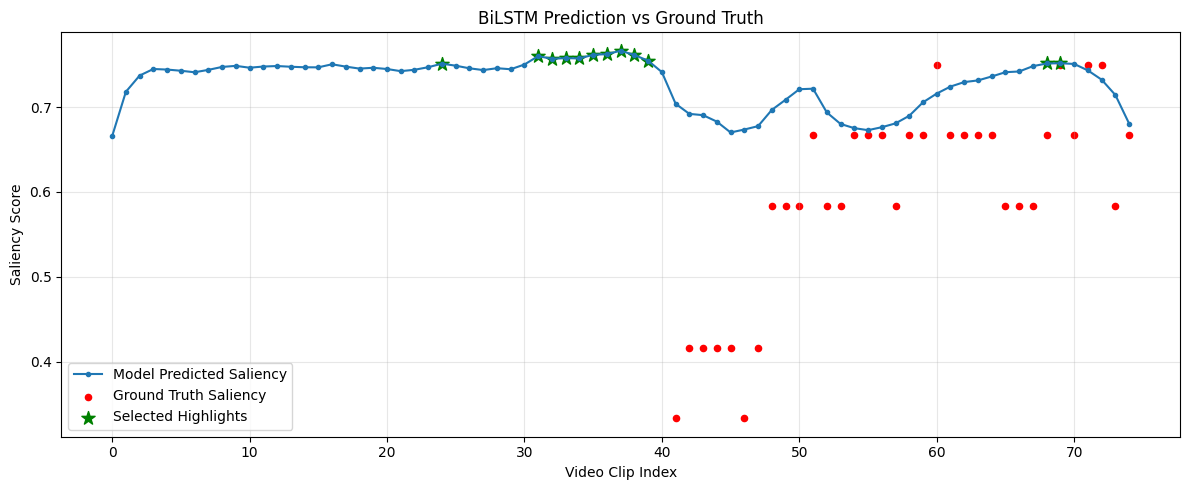

In [24]:

import matplotlib.pyplot as plt
import numpy as np
import math

# Load the best trained model
model.load_state_dict(
    torch.load(
        "/kaggle/working/qvhighlight_bilstm_best.pth",
        map_location=DEVICE
    )
)
model.eval()

# Select a validation example with ground-truth labels
sample_index = next(
    i for i, record in enumerate(val_dataset.valid_records)
    if "relevant_clip_ids" in record
    and len(record["relevant_clip_ids"]) > 0
)

record = val_dataset.valid_records[sample_index]

features, targets, mask = val_dataset[sample_index]

# Generate predictions
with torch.no_grad():
    x = features.unsqueeze(0).to(DEVICE)
    predictions = model(x).squeeze(0).cpu().numpy()

targets = targets.numpy()
mask = mask.numpy()

# Select top 15% clips
num_clips = len(predictions)
k = max(1, math.ceil(num_clips * 0.15))

selected = np.argsort(predictions)[-k:]
selected = sorted(selected.tolist())

# Display example information
print("=" * 55)
print("QVHIGHLIGHTS BiLSTM - LIVE DEMONSTRATION")
print("=" * 55)

print("Video ID:", record["vid"])
print("Query:", record["query"])
print("Video duration:", record["duration"], "seconds")
print("Total clips:", num_clips)
print("Selected highlight clips:", selected)
print("Number of selected clips:", len(selected))
print("Selection ratio:", round(k / num_clips, 4))

# Display selected clip scores
print("\nSELECTED HIGHLIGHTS")
for clip in selected:
    print(
        f"Clip {clip}: "
        f"Predicted saliency = {predictions[clip]:.4f}"
    )

# Plot predicted scores and annotated ground truth
plt.figure(figsize=(12, 5))

plt.plot(
    predictions,
    label="Model Predicted Saliency",
    marker="o",
    markersize=3
)

ground_truth = np.where(mask > 0, targets, np.nan)

plt.scatter(
    np.arange(num_clips),
    ground_truth,
    label="Ground Truth Saliency",
    color="red",
    s=20
)

plt.scatter(
    selected,
    predictions[selected],
    label="Selected Highlights",
    color="green",
    marker="*",
    s=100
)

plt.xlabel("Video Clip Index")
plt.ylabel("Saliency Score")
plt.title("BiLSTM Prediction vs Ground Truth")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/single_video_demo.png",
    dpi=300
)

plt.show()


In [25]:

# Convert selected clip indices into video timestamps

duration = float(record["duration"])
clip_duration = duration / num_clips

print("QUERY:", record["query"])
print("\nSELECTED VIDEO HIGHLIGHTS")
print("-" * 55)

highlight_intervals = []

for clip in selected:
    start_time = clip * clip_duration
    end_time = min((clip + 1) * clip_duration, duration)

    interval = {
        "clip": clip,
        "start": round(start_time, 2),
        "end": round(end_time, 2),
        "predicted_score": round(float(predictions[clip]), 4),
        "ground_truth_score": round(float(targets[clip]), 4)
        if mask[clip] > 0 else None
    }

    highlight_intervals.append(interval)

    print(
        f"Clip {clip:02d} | "
        f"{start_time:.2f}s - {end_time:.2f}s | "
        f"Predicted: {predictions[clip]:.4f} | "
        f"Ground truth: "
        f"{interval['ground_truth_score']}"
    )

# Save timestamp results
pd.DataFrame(highlight_intervals).to_csv(
    "/kaggle/working/single_video_highlights.csv",
    index=False
)

print("\nTimestamp file saved successfully!")


QUERY: A girl and her mother cooked while talking with each other on facetime.

SELECTED VIDEO HIGHLIGHTS
-------------------------------------------------------
Clip 24 | 48.00s - 50.00s | Predicted: 0.7510 | Ground truth: None
Clip 31 | 62.00s - 64.00s | Predicted: 0.7599 | Ground truth: None
Clip 32 | 64.00s - 66.00s | Predicted: 0.7567 | Ground truth: None
Clip 33 | 66.00s - 68.00s | Predicted: 0.7576 | Ground truth: None
Clip 34 | 68.00s - 70.00s | Predicted: 0.7572 | Ground truth: None
Clip 35 | 70.00s - 72.00s | Predicted: 0.7615 | Ground truth: None
Clip 36 | 72.00s - 74.00s | Predicted: 0.7622 | Ground truth: None
Clip 37 | 74.00s - 76.00s | Predicted: 0.7663 | Ground truth: None
Clip 38 | 76.00s - 78.00s | Predicted: 0.7612 | Ground truth: None
Clip 39 | 78.00s - 80.00s | Predicted: 0.7545 | Ground truth: None
Clip 68 | 136.00s - 138.00s | Predicted: 0.7512 | Ground truth: 0.6667
Clip 69 | 138.00s - 140.00s | Predicted: 0.7515 | Ground truth: 0.75

Timestamp file saved succes

In [26]:

demo_df = pd.DataFrame(highlight_intervals)

demo_df = demo_df.rename(columns={
    "clip": "Clip Number",
    "start": "Start Time (s)",
    "end": "End Time (s)",
    "predicted_score": "Predicted Score",
    "ground_truth_score": "Ground Truth"
})

print("VIDEO QUERY:")
print(record["query"])

print("\nMODEL-GENERATED HIGHLIGHTS:")
display(demo_df)

print("\nTotal selected clips:", len(demo_df))
print("Annotated selected clips:",
      demo_df["Ground Truth"].notna().sum())


VIDEO QUERY:
A girl and her mother cooked while talking with each other on facetime.

MODEL-GENERATED HIGHLIGHTS:


,Clip Number,Start Time (s),End Time (s),Predicted Score,Ground Truth
0,24,48.0,50.0,0.7510,NaN
1,31,62.0,64.0,0.7599,NaN
2,32,64.0,66.0,0.7567,NaN
3,33,66.0,68.0,0.7576,NaN
4,34,68.0,70.0,0.7572,NaN
5,35,70.0,72.0,0.7615,NaN
6,36,72.0,74.0,0.7622,NaN
7,37,74.0,76.0,0.7663,NaN
8,38,76.0,78.0,0.7612,NaN
9,39,78.0,80.0,0.7545,NaN



Total selected clips: 12
Annotated selected clips: 2


In [28]:

threshold = 0.76

adaptive_results = []

for item in test_highlights:
    scores = np.array(item["saliency_scores"])

    # Select clips based on predicted saliency
    selected_indices = np.where(scores >= threshold)[0].tolist()

    # Ensure at least one clip is selected
    if len(selected_indices) == 0:
        selected_indices = [int(np.argmax(scores))]

    total_clips = len(scores)
    selected_count = len(selected_indices)

    compression_ratio = selected_count / total_clips

    adaptive_results.append({
        "Video ID": item["vid"],
        "Total Clips": total_clips,
        "Selected Clips": selected_count,
        "Compression Ratio": round(compression_ratio, 4),
        "Compression (%)": round(compression_ratio * 100, 2)
    })

adaptive_df = pd.DataFrame(adaptive_results)

print("ADAPTIVE COMPRESSION RESULTS")
display(adaptive_df.sample(20, random_state=42))

print("\nAverage compression ratio:",
      round(adaptive_df["Compression Ratio"].mean(), 4))

print("Average selected clips:",
      round(adaptive_df["Selected Clips"].mean(), 2))

print("Minimum selected clips:", adaptive_df["Selected Clips"].min())
print("Maximum selected clips:", adaptive_df["Selected Clips"].max())


ADAPTIVE COMPRESSION RESULTS


,Video ID,Total Clips,Selected Clips,Compression Ratio,Compression (%)
1492,LmnfadjuaE8_210.0_360.0,75,1,0.0133,1.33
1156,o0fdleH293A_360.0_510.0,75,66,0.8800,88.00
1253,1IDUWll4TXo_210.0_360.0,75,1,0.0133,1.33
561,zvEaxc9WD14_510.0_660.0,75,5,0.0667,6.67
1098,i0dywTgTRy4_210.0_360.0,75,57,0.7600,76.00
582,kr_sTfYX_FI_210.0_360.0,75,1,0.0133,1.33
1511,7bx2_WbwlKo_210.0_360.0,75,58,0.7733,77.33
1322,dcAFJS34zkE_60.0_210.0,75,14,0.1867,18.67
1202,gS7RgLgSw-o_60.0_210.0,75,26,0.3467,34.67
1320,izWkhAfNNQg_360.0_510.0,75,3,0.0400,4.00



Average compression ratio: 0.3753
Average selected clips: 28.04
Minimum selected clips: 1
Maximum selected clips: 75
